# California Wildfire Risk: How It Works
**Angel Cruz · Research project**

What weather conditions accompanied historical California fires? This notebook joins the project's saved fire and weather records, calculates a transparent score, and visualizes the results.

**Start here:** Choose **Runtime → Run all** in Google Colab. No API key, Drive mount, or GPU is needed. Colab downloads the saved CSV from GitHub automatically. To experiment, save your own copy and change the weather inputs below.

The analysis loads the saved dataset with pandas, checks for missing weather values, normalizes the measurements, and combines them into a weighted score. Charts show how those scores vary across the recorded fires. The saved snapshot makes the results reproducible without live API calls.

**Scope:** The score describes weather conditions associated with recorded fires. It is not a probability of ignition, an acreage forecast, or an emergency warning. The data contains fires, not a comparison group of places and days without fires.


## 1. Data sources and loading
The project uses a pandas DataFrame to store and process the fire and weather records. The saved CSV is stored separately in [`data/wildfire_weather_merged.csv`](data/wildfire_weather_merged.csv). The short loader below reads it locally or downloads the same snapshot from this GitHub repository in Colab; it does not fetch fresh API data. API failures remain visible as missing weather values.

The original pipeline is `calfire_api.py → weather_api.py → analysis.py → charts/maps`. CAL FIRE supplies event names, dates, acres, and centroid coordinates. Open-Meteo supplies historical reanalysis weather near those coordinates. The weather window runs from seven days before the alarm date **through the alarm date**, inclusive (eight calendar days). It therefore includes event-day weather and is not a strictly pre-ignition forecast.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Read the saved snapshot locally, or download it when running in Colab.
filename = "wildfire_weather_merged.csv"
local_paths = [Path("data") / filename, Path("notebooks/data") / filename]
snapshot_url = (
    "https://raw.githubusercontent.com/AngelCruzGtur/"
    "angelcruzgtur.github.io/main/notebooks/data/" + filename
)
data_source = next((path for path in local_paths if path.is_file()), snapshot_url)
raw = pd.read_csv(data_source, parse_dates=["alarm_date"])
print(f"Snapshot: {len(raw):,} fire records; years {raw['year'].min()}–{raw['year'].max()}")
display(raw.head())


Snapshot: 2,000 fire records; years 2021–2025


,fire_name,year,alarm_date,latitude,longitude,acres,weather_start,weather_end,max_temperature_f,min_relative_humidity_pct,total_precipitation_in,max_wind_speed_mph,mean_soil_moisture,weather_error
0,GIFFORD,2025,2025-08-01,35.131037,-120.151219,131613.50,2025-07-25,2025-08-01,87.6,22.0,0.000,12.1,0.068000,NaN
1,MADRE,2025,2025-07-02,35.116913,-119.893337,80779.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,429 Client Error: Too Many Requests for url: h...
2,GARNET,2025,2025-08-24,36.949439,-119.081283,60019.23,2025-08-17,2025-08-24,83.0,16.0,0.075,11.5,0.227250,NaN
3,SALT,2025,2025-09-02,35.992597,-120.338306,25553.55,2025-08-26,2025-09-02,98.9,9.0,0.004,12.4,0.143125,NaN
4,PALISADES,2025,2025-01-07,34.072646,-118.574212,23448.88,2024-12-31,2025-01-07,71.1,11.0,0.000,22.9,0.103250,NaN


## 2. Missing weather data
Weather columns use °F, percent relative humidity, mph, inches of accumulated rain, and volumetric soil moisture (m³/m³). We exclude rows missing any scoring input rather than treating missing weather as zero. This can bias the remaining sample if API failures are unevenly distributed.


In [2]:
FEATURES = ["max_temperature_f", "min_relative_humidity_pct", "max_wind_speed_mph",
            "total_precipitation_in", "mean_soil_moisture"]
for column in FEATURES:
    raw[column] = pd.to_numeric(raw[column], errors="coerce")
display(raw[FEATURES].isna().sum().rename("missing_rows").to_frame())
clean = raw.dropna(subset=FEATURES).copy()
print(f"Using {len(clean):,} complete records; excluding {len(raw) - len(clean):,} incomplete records.")
assert len(clean) > 0, "No complete weather records are available."
display(clean[FEATURES].describe().round(2))


,missing_rows
max_temperature_f,443
min_relative_humidity_pct,443
max_wind_speed_mph,443
total_precipitation_in,443
mean_soil_moisture,443


Using 1,557 complete records; excluding 443 incomplete records.


,max_temperature_f,min_relative_humidity_pct,max_wind_speed_mph,total_precipitation_in,mean_soil_moisture
count,1557.00,1557.00,1557.00,1557.00,1557.00
mean,93.16,13.25,13.33,0.07,0.13
std,11.56,8.89,4.06,0.27,0.08
min,50.10,2.00,5.40,0.00,0.00
25%,86.50,8.00,10.40,0.00,0.08
50%,94.70,11.00,12.50,0.00,0.12
75%,101.40,15.00,15.40,0.02,0.16
max,120.70,80.00,33.10,3.28,0.50


## 3. How the score is calculated
Different units cannot be averaged directly. We first map each measurement to 0–100 using `(value − low) / (high − low) × 100`, clipping values outside the chosen bounds. Humidity, precipitation, and soil moisture are reversed so that drier conditions score higher.

| Factor | Normalization bounds | Weight |
|---|---|---|
| Maximum temperature | 65–115 °F | 25% |
| Minimum relative humidity | 5–70% (reversed) | 25% |
| Maximum wind speed | 0–55 mph | 20% |
| Total precipitation | 0–1.5 inches (reversed) | 15% |
| Mean soil moisture | 0.05–0.45 m³/m³ (reversed) | 15% |

These are project design choices, not calibrated scientific alert thresholds. The scoring function below is copied from `src/analysis.py`.


In [3]:
def _scaled(series: pd.Series, low: float, high: float) -> pd.Series:
    numeric = pd.to_numeric(series, errors="coerce")
    return ((numeric - low) / (high - low) * 100).clip(0, 100)


def calculate_risk_scores(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()

    temperature = _scaled(result["max_temperature_f"], 65, 115)
    humidity_dryness = 100 - _scaled(result["min_relative_humidity_pct"], 5, 70)
    wind = _scaled(result["max_wind_speed_mph"], 0, 55)
    precipitation_dryness = 100 - _scaled(result["total_precipitation_in"], 0, 1.5)
    soil_dryness = 100 - _scaled(result["mean_soil_moisture"], 0.05, 0.45)

    result["temperature_component"] = temperature
    result["humidity_component"] = humidity_dryness
    result["wind_component"] = wind
    result["precipitation_component"] = precipitation_dryness
    result["soil_component"] = soil_dryness

    result["risk_score"] = (
        0.25 * temperature
        + 0.25 * humidity_dryness
        + 0.20 * wind
        + 0.15 * precipitation_dryness
        + 0.15 * soil_dryness
    ).round(1)

    result["risk_category"] = pd.cut(
        result["risk_score"],
        bins=[-1, 35, 55, 75, 100],
        labels=["Low", "Moderate", "High", "Very High"],
    )

    return result.sort_values("risk_score", ascending=False).reset_index(drop=True)

In [4]:
ranked = calculate_risk_scores(clean)
display(ranked[["fire_name", "year", "acres", "risk_score", "risk_category"]].head(15))


,fire_name,year,acres,risk_score,risk_category
0,LOST HILLS,2024,4044.124000,86.0,Very High
1,5 INCIDENT,2024,347.292400,86.0,Very High
2,HOLLOWAY,2024,121.712900,86.0,Very High
3,BLUE WATER,2024,215.105000,85.5,Very High
4,18,2024,0.011812,85.3,Very High
5,10TH,2024,131.961300,84.2,Very High
6,DESERT,2021,216.621500,84.1,Very High
7,68,2021,219.728200,84.0,Very High
8,SKYLINE,2024,9.860471,83.8,Very High
9,CLEAR,2024,8.168558,83.7,Very High


## 4. Results and visualizations
The first chart shows the highest scores **within this snapshot**. The scatterplot compares temperature and humidity; color shows the score and point size shows wind speed. Because these variables are part of the formula, a visual relationship with the score is expected and does not independently validate it.


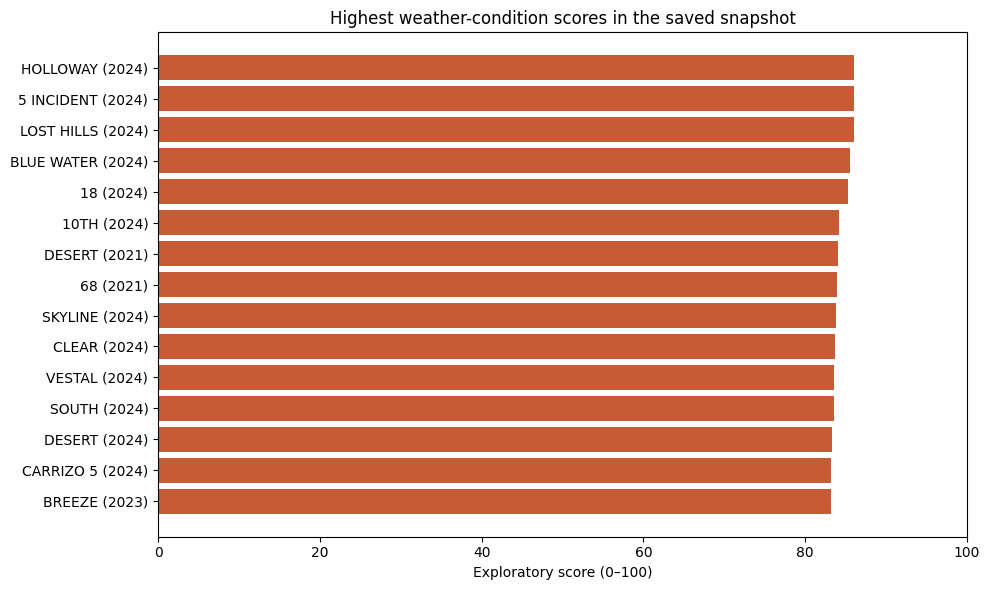

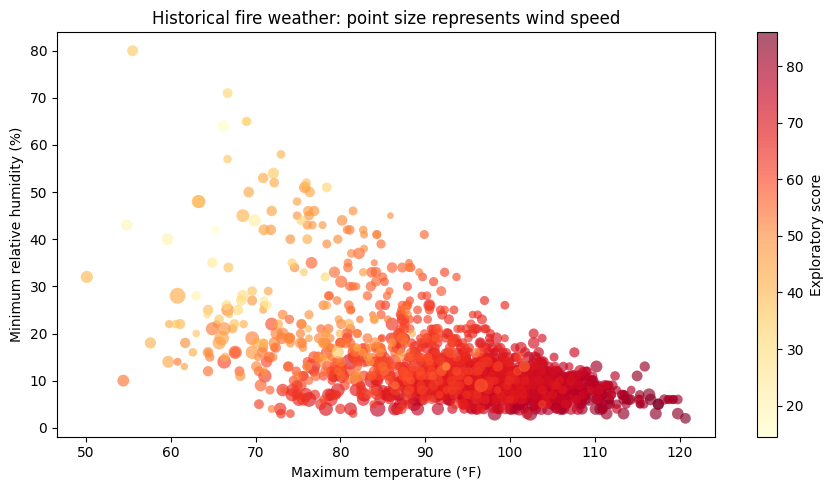

In [5]:
top = ranked.head(15).sort_values("risk_score")
fig, ax = plt.subplots(figsize=(10, 6))
labels = top["fire_name"].astype(str) + " (" + top["year"].astype(str) + ")"
ax.barh(range(len(top)), top["risk_score"], color="#c65b36")
ax.set_yticks(range(len(top)), labels)
ax.set(xlabel="Exploratory score (0–100)", xlim=(0, 100), title="Highest weather-condition scores in the saved snapshot")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
points = ax.scatter(ranked["max_temperature_f"], ranked["min_relative_humidity_pct"],
                    c=ranked["risk_score"], s=ranked["max_wind_speed_mph"].clip(lower=1) * 4,
                    cmap="YlOrRd", alpha=0.65, edgecolors="none")
fig.colorbar(points, ax=ax, label="Exploratory score")
ax.set(xlabel="Maximum temperature (°F)", ylabel="Minimum relative humidity (%)",
       title="Historical fire weather: point size represents wind speed")
fig.tight_layout()
plt.show()


## 5. Interactive weather scenario
The five editable inputs below use the same scoring function as the historical records. Rerunning the cell updates the score and contribution chart. The category boundaries are Low ≤35, Moderate >35–55, High >55–75, and Very High >75. The bars show each factor's **weighted contribution**, which sums to the displayed score before rounding.

Lower humidity increases the dryness contribution, while more rain reduces the precipitation contribution. These are hypothetical weather inputs, not a live forecast for a location.


Scenario score: 73.4/100 (High)


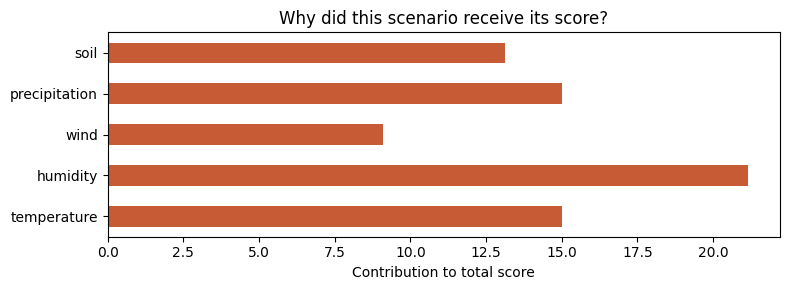

In [6]:
# Edit these inputs, then run this cell.
temperature_f = 95.0
humidity_pct = 15.0
wind_mph = 25.0
precipitation_in = 0.0
soil_moisture = 0.10

assert 0 <= humidity_pct <= 100
assert wind_mph >= 0 and precipitation_in >= 0 and 0 <= soil_moisture <= 1
scenario = pd.DataFrame([{
    "max_temperature_f": temperature_f, "min_relative_humidity_pct": humidity_pct,
    "max_wind_speed_mph": wind_mph, "total_precipitation_in": precipitation_in,
    "mean_soil_moisture": soil_moisture,
}])
result = calculate_risk_scores(scenario).iloc[0]
print(f"Scenario score: {result['risk_score']:.1f}/100 ({result['risk_category']})")
weights = {"temperature": .25, "humidity": .25, "wind": .20, "precipitation": .15, "soil": .15}
contributions = pd.Series({name: result[f"{name}_component"] * weight for name, weight in weights.items()})
contributions.plot.barh(figsize=(8, 3), color="#c65b36")
plt.xlabel("Contribution to total score")
plt.title("Why did this scenario receive its score?")
plt.tight_layout()
plt.show()


## 6. Results export
The cell writes a CSV in the notebook's working directory. In Colab, download it from the Files sidebar. Runtime files are temporary; download anything you want to keep.


In [7]:
export_path = Path("wildfire_risk_colab_results.csv")
ranked.to_csv(export_path, index=False)
print(f"Saved {len(ranked):,} scored records to {export_path}")


Saved 1,557 scored records to wildfire_risk_colab_results.csv


## 7. Interpretation and limitations
- **Historical association:** Hot, dry, windy conditions contribute to the chosen score. A high score does not establish causation or predict an individual fire's size.
- **Selection:** Recorded fire perimeters and complete weather rows are not a representative sample of every California location or day. Repeated names can describe different events.
- **Resolution:** Weather at a perimeter centroid cannot represent every part of a large fire. Terrain, fuels, suppression, and ignition sources are absent.
- **Timing:** The inclusive weather window contains the alarm day. A forecasting extension should use only information available before the prediction time.
- **Experimental models:** The repository also has PyTorch acreage regression and large-fire classification. The README reports weak regression performance and modest classification ranking performance. Those are previous run results, not models retrained by this notebook. A stronger evaluation would reserve later years for testing and compare to simple baselines; selecting the best epoch requires a validation set separate from that final test set.

**Possible extensions:** Comparisons across years, analysis of missingness by year, and sensitivity checks on how the weights affect rankings. A map of recorded fires would show their locations, not ignition probability across unobserved areas.

## Code guide and sources
| File | Responsibility |
|---|---|
| `src/main.py` | Runs the collection, merge, scoring, chart, and map pipeline |
| `src/calfire_api.py` | Retrieves historical fire records |
| `src/weather_api.py` | Retrieves and summarizes the inclusive weather window |
| `src/analysis.py` | Calculates scores and creates charts |
| `src/maps.py` | Creates geographic visualizations |
| `src/predictive_model.py` | Defines experimental neural networks and training |

- [CAL FIRE historical fire perimeters](https://www.fire.ca.gov/what-we-do/fire-resource-assessment-program/fire-perimeters)
- [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)

This notebook embeds the existing local project snapshot; it does not refresh the source data. For a fresh collection, use the full repository and its README commands. Live API requests may be rate limited.
